# TFT Forecasting & Digital Twin Validation
## Stratified + Chronological Split Version

**How to switch modes:** change `SPLIT_MODE = "stratified"` ↔ `"chrono"` in Cell 3 and re-run top to bottom. Every downstream cell adapts automatically.

In [1]:
# ============================================================
# 1. INSTALLS
# ============================================================
!pip -q install xgboost imbalanced-learn optuna shap

# Phase 1 — Data Loading & Problem Definition

In [2]:
# ============================================================
# 2. IMPORTS & CONFIG
# ============================================================
import os, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, accuracy_score,
)
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 200)

Device: cuda


In [3]:
# ============================================================
# 3. SPLIT MODE CONFIG
#    "stratified"  → original behaviour (reproduce Milestone-3 numbers)
#    "chrono"      → chronological split (IRAI revision)
#
#    AI4I has no real time axis → chrono = row-index order.
#    Windows sorted by window_start, split 70/15/15,
#    with GAP_BUFFER = HORIZON_K windows dropped at each
#    split boundary to prevent look-ahead leakage.
# ============================================================
SPLIT_MODE  = "stratified"   # <── change to "chrono" for revision runs
SPLIT_SUFFIX = f"_{SPLIT_MODE}"
GAP_BUFFER   = 10            # = HORIZON_K

print(f"SPLIT_MODE = {SPLIT_MODE!r}   (artifacts will include '{SPLIT_SUFFIX}' suffix)")

SPLIT_MODE = 'stratified'   (artifacts will include '_stratified' suffix)


In [4]:
# ============================================================
# 4. LOAD DATA
# ============================================================
CSV_PATH = "/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv"
assert os.path.exists(CSV_PATH), f"File not found: {CSV_PATH}"
df_raw = pd.read_csv(CSV_PATH)
print("Loaded:", df_raw.shape)
df_raw.head(3)

Loaded: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


In [5]:
# ============================================================
# 5. STANDARDIZE COLUMN NAMES
# ============================================================
rename_map = {
    "Air temperature [K]":      "AirTemp",
    "Process temperature [K]":  "ProcessTemp",
    "Rotational speed [rpm]":   "RotSpeed",
    "Torque [Nm]":              "Torque",
    "Tool wear [min]":          "ToolWear",
    "Machine failure":          "MachineFailure",
    "UDI": "UID", "Product ID": "ProductID", "Type": "Type",
    "TWF":"TWF","HDF":"HDF","PWF":"PWF","OSF":"OSF","RNF":"RNF",
}
df_raw = df_raw.rename(columns=rename_map)
required = ["AirTemp","ProcessTemp","RotSpeed","Torque","ToolWear",
            "MachineFailure","TWF","HDF","PWF","OSF","RNF"]
missing = [c for c in required if c not in df_raw.columns]
if missing: raise ValueError(f"Missing columns: {missing}")
print("Columns OK")

Columns OK


In [6]:
# ============================================================
# 6. CLEAN & CAST
# ============================================================
df = df_raw.copy()
numeric_cols = ["AirTemp","ProcessTemp","RotSpeed","Torque","ToolWear",
                "MachineFailure","TWF","HDF","PWF","OSF","RNF"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=numeric_cols).reset_index(drop=True)
for col in ["MachineFailure","TWF","HDF","PWF","OSF","RNF"]:
    df[col] = df[col].astype(int)
print(f"Shape: {df.shape}  |  Failure rate: {df['MachineFailure'].mean():.4f}")

Shape: (10000, 14)  |  Failure rate: 0.0339


# Phase 2 — Physics-Based Feature Engineering

In [7]:
# ============================================================
# 7. PHYSICS-INFORMED FEATURE ENGINEERING
# ============================================================
eps = 1e-6
df["Power"]      = df["Torque"] * df["RotSpeed"]
df["TempDiff"]   = df["ProcessTemp"] - df["AirTemp"]
df["ToolStrain"] = df["ToolWear"] * df["Torque"]
df["Torque_over_RotSpeed"] = df["Torque"] / (df["RotSpeed"] + eps)
df["Power_over_ToolWear"]  = df["Power"]  / (df["ToolWear"] + 1.0)
df["HeatRate"]   = df["Power"]    / (df["TempDiff"] + eps)
df["WearRate"]   = df["ToolWear"] / (df["RotSpeed"] + eps)
df["TorqueEff"]  = df["Torque"]   / (df["Power"]    + eps)
df["TempPower"]  = df["TempDiff"] * df["Power"]

BASE_FEATURES = ["AirTemp","ProcessTemp","RotSpeed","Torque","ToolWear"]
ENG_FEATURES  = ["Power","TempDiff","ToolStrain","Torque_over_RotSpeed",
                 "Power_over_ToolWear","HeatRate","WearRate","TorqueEff","TempPower"]
ALL_FEATURES  = BASE_FEATURES + ENG_FEATURES
print(f"Total features: {len(ALL_FEATURES)}")

Total features: 14


In [8]:
# ============================================================
# 8. FAILURE TYPE LABEL (priority: HDF > PWF > OSF > TWF > RNF)
# ============================================================
def get_failure_type(row):
    for col, name in [("HDF","HDF"),("PWF","PWF"),("OSF","OSF"),("TWF","TWF"),("RNF","RNF")]:
        if row[col] == 1: return name
    return "Healthy"

df["FailureType"] = df.apply(get_failure_type, axis=1)
print(df["FailureType"].value_counts())

FailureType
Healthy    9652
HDF         115
PWF          92
OSF          80
TWF          43
RNF          18
Name: count, dtype: int64


In [ ]:
# ============================================================
# 9. NORMALIZE (MinMax to [0,1])
#    IMPORTANT: scaler is fit on the FULL dataset here.
#    Under chrono mode this is acceptable for
#    forecasting/DT work because the TFT operates in scaled
#    space — the key leakage risk is in the detection split.
#    If you want strict chrono scaling,
#    fit scaler only on train rows (indices known after Cell 11).
# ============================================================
scaler = MinMaxScaler()
df_scaled = df.copy()
df_scaled[ALL_FEATURES] = scaler.fit_transform(df_scaled[ALL_FEATURES])

print("Scale check — min:", np.round(df_scaled[ALL_FEATURES].min().min(), 6),
      " max:", np.round(df_scaled[ALL_FEATURES].max().max(), 6))

Scale check — min: 0.0  max: 1.0


In [10]:
# ============================================================
# 10. WINDOW CONFIG
# ============================================================
WINDOW_SIZE = 20
HORIZON_K   = 10
print(f"W={WINDOW_SIZE}, K={HORIZON_K}")

W=20, K=10


# Phase 3 — Sliding Window & Horizon Labeling

In [11]:
# ============================================================
# 11. SLIDING WINDOW FEATURE EXTRACTION
# ============================================================
def compute_slope(x):
    t = np.arange(len(x))
    return 0.0 if np.allclose(x, x[0]) else float(np.polyfit(t, x, 1)[0])

def extract_window_stats(window_2d, feature_names):
    stats = {}
    for j, name in enumerate(feature_names):
        x = window_2d[:, j]
        d = np.diff(x)
        stats[f"{name}_mean"]            = float(np.mean(x))
        stats[f"{name}_std"]             = float(np.std(x))
        stats[f"{name}_min"]             = float(np.min(x))
        stats[f"{name}_max"]             = float(np.max(x))
        stats[f"{name}_range"]           = float(np.ptp(x))
        stats[f"{name}_slope"]           = compute_slope(x)
        stats[f"{name}_delta"]           = float(x[-1] - x[0])
        stats[f"{name}_last"]            = float(x[-1])
        stats[f"{name}_last_minus_mean"] = float(x[-1] - np.mean(x))
        stats[f"{name}_mean_abs_diff"]   = float(np.mean(np.abs(d))) if len(d) else 0.0
        stats[f"{name}_std_diff"]        = float(np.std(d))          if len(d) else 0.0
        stats[f"{name}_max_jump"]        = float(np.max(np.abs(d)))  if len(d) else 0.0
    return stats

def build_windows(df_in, feature_names, window_size=20, horizon_k=10):
    X_seq, rows = [], []
    values   = df_in[feature_names].values
    y_binary = df_in["MachineFailure"].values
    y_type   = df_in["FailureType"].values
    max_start = len(df_in) - window_size - horizon_k

    for start in range(max_start):
        end           = start + window_size
        future_binary = y_binary[end : end + horizon_k]
        future_types  = y_type  [end : end + horizon_k]

        target_binary     = int(np.any(future_binary == 1))
        target_type       = "Healthy"
        first_fail_offset = np.nan
        if target_binary == 1:
            fidx              = int(np.where(future_binary == 1)[0][0])
            target_type       = future_types[fidx]
            first_fail_offset = fidx + 1

        row = extract_window_stats(values[start:end], feature_names)
        row.update({
            "target_binary":       target_binary,
            "target_type":         target_type,
            "window_start":        start,
            "window_end":          end - 1,
            "future_start":        end,
            "future_end":          end + horizon_k - 1,
            "first_failure_offset": first_fail_offset,
        })
        rows.append(row)
        X_seq.append(values[start:end])

    features_df = pd.DataFrame(rows)
    X_seq       = np.array(X_seq, dtype=np.float32)
    return features_df, X_seq

features_df, X_seq = build_windows(df_scaled, ALL_FEATURES, WINDOW_SIZE, HORIZON_K)
print("Tabular features:", features_df.shape)
print("Sequences:       ", X_seq.shape)
print()
print("Binary label distribution:")
print(features_df["target_binary"].value_counts())

Tabular features: (9970, 175)
Sequences:        (9970, 20, 14)

Binary label distribution:
target_binary
0    7500
1    2470
Name: count, dtype: int64


In [12]:
# ============================================================
# 12. SPLIT  (stratified OR chronological — controlled by SPLIT_MODE)
#
#  STRATIFIED (original):
#    • Random 70/15/15 with stratify=y
#    • Preserves class balance in each split
#    • Risk: temporal leakage — future windows may appear in train
#
#  CHRONO (revision):
#    • Sort all windows by window_start (row-index order)
#    • First 70% → train, next 15% → valid, last 15% → test
#    • Drop last GAP_BUFFER=10 windows of train and valid to
#      prevent look-ahead horizon from spilling into the next split
#    • Asserts non-overlapping window_start ranges
# ============================================================
feature_cols = [c for c in features_df.columns if c not in [
    "target_binary","target_type","window_start","window_end",
    "future_start","future_end","first_failure_offset"]]

X       = features_df[feature_cols].copy()
y       = features_df["target_binary"].copy()
idx_all = np.arange(len(features_df))

if SPLIT_MODE == "stratified":
    # ── original behaviour ──────────────────────────────────
    X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
        X, y, idx_all, test_size=0.30, stratify=y, random_state=SEED)
    X_valid, X_test, y_valid, y_test, idx_valid, idx_test = train_test_split(
        X_temp, y_temp, idx_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

elif SPLIT_MODE == "chrono":
    # ── chronological split with gap buffer ─────────────────
    sort_order = features_df["window_start"].values.argsort()
    n_total    = len(sort_order)
    n_tr       = int(0.70 * n_total)
    n_va       = int(0.15 * n_total)

    train_pos = sort_order[:n_tr]
    valid_pos = sort_order[n_tr : n_tr + n_va]
    test_pos  = sort_order[n_tr + n_va :]

    if GAP_BUFFER > 0:
        train_pos = train_pos[:-GAP_BUFFER] if len(train_pos) > GAP_BUFFER else train_pos
        valid_pos = valid_pos[:-GAP_BUFFER] if len(valid_pos) > GAP_BUFFER else valid_pos

    idx_train = idx_all[train_pos]
    idx_valid = idx_all[valid_pos]
    idx_test  = idx_all[test_pos]

    X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
    X_valid, y_valid = X.iloc[idx_valid], y.iloc[idx_valid]
    X_test,  y_test  = X.iloc[idx_test],  y.iloc[idx_test]
else:
    raise ValueError(f"Unknown SPLIT_MODE = {SPLIT_MODE!r}")

# Sequence slices
X_seq_train = X_seq[idx_train]
X_seq_valid = X_seq[idx_valid]
X_seq_test  = X_seq[idx_test]
y_train_np  = y_train.values.astype(np.float32)
y_valid_np  = y_valid.values.astype(np.float32)
y_test_np   = y_test.values.astype(np.float32)

print(f"SPLIT_MODE = {SPLIT_MODE}")
print(f"Train : {X_train.shape}  pos_rate={y_train.mean():.4f}")
print(f"Valid : {X_valid.shape}  pos_rate={y_valid.mean():.4f}")
print(f"Test  : {X_test.shape}  pos_rate={y_test.mean():.4f}")

if SPLIT_MODE == "chrono":
    tr_range = (features_df.iloc[idx_train]["window_start"].min(),
                features_df.iloc[idx_train]["window_start"].max())
    va_range = (features_df.iloc[idx_valid]["window_start"].min(),
                features_df.iloc[idx_valid]["window_start"].max())
    te_range = (features_df.iloc[idx_test]["window_start"].min(),
                features_df.iloc[idx_test]["window_start"].max())
    print(f"\nWindow-start ranges (must be non-overlapping):")
    print(f"  Train : {tr_range}")
    print(f"  Valid : {va_range}")
    print(f"  Test  : {te_range}")
    assert tr_range[1] < va_range[0], "TRAIN/VAL leakage!"
    assert va_range[1] < te_range[0], "VAL/TEST leakage!"
    print("✓ No overlap between splits.")

SPLIT_MODE = stratified
Train : (6979, 168)  pos_rate=0.2477
Valid : (1495, 168)  pos_rate=0.2475
Test  : (1496, 168)  pos_rate=0.2480


# Phase 5 — Early Failure Prediction (XGBoost)

In [13]:
# ============================================================
# 13. TRAIN XGBOOST BINARY DETECTOR  (Optuna-tuned)
# ============================================================
!pip -q install optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos_weight = neg / max(1, pos)
print(f"Negative/Positive ratio: {scale_pos_weight:.1f}x")

def xgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 800),
        "max_depth":         trial.suggest_int("max_depth", 3, 8),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
        "gamma":             trial.suggest_float("gamma", 0.0, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "objective":         "binary:logistic",
        "eval_metric":       "aucpr",
        "scale_pos_weight":  scale_pos_weight,
        "random_state":      SEED,
        "verbosity":         0,
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scores = []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        Xtr, Xva = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        ytr, yva = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        m = XGBClassifier(**params)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        p = m.predict_proba(Xva)[:, 1]
        scores.append(average_precision_score(yva, p))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(xgb_objective, n_trials=60, show_progress_bar=True)

best_params = study.best_params
best_params.update({
    "objective": "binary:logistic", "eval_metric": "aucpr",
    "scale_pos_weight": scale_pos_weight, "random_state": SEED, "verbosity": 0,
})
print(f"\nBest CV Avg-Precision: {study.best_value:.4f}")

xgb_bin = XGBClassifier(**best_params)
xgb_bin.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

valid_proba = xgb_bin.predict_proba(X_valid)[:, 1]
test_proba  = xgb_bin.predict_proba(X_test)[:, 1]

print(f"\nValidation ROC-AUC : {roc_auc_score(y_valid, valid_proba):.4f}")
print(f"Validation Avg Prec: {average_precision_score(y_valid, valid_proba):.4f}")

Negative/Positive ratio: 3.0x


  0%|          | 0/60 [00:00<?, ?it/s]


Best CV Avg-Precision: 0.9394

Validation ROC-AUC : 0.9908
Validation Avg Prec: 0.9681


In [14]:
# ============================================================
# 14. THRESHOLD SWEEP
# ============================================================
def threshold_sweep(y_true, y_prob, thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.05)
    rows = []
    for thr in thresholds:
        yp = (y_prob >= thr).astype(int)
        rows.append({
            "threshold": round(float(thr), 3),
            "precision": precision_score(y_true, yp, zero_division=0),
            "recall":    recall_score(y_true, yp, zero_division=0),
            "f1":        f1_score(y_true, yp, zero_division=0),
        })
    return pd.DataFrame(rows)

sweep_valid = threshold_sweep(y_valid.values, valid_proba)
BEST_THRESHOLD = float(sweep_valid.sort_values(["f1","recall"], ascending=False).iloc[0]["threshold"])
print(f"Best threshold (val F1): {BEST_THRESHOLD}  [SPLIT_MODE={SPLIT_MODE}]")

y_test_pred = (test_proba >= BEST_THRESHOLD).astype(int)

print()
print(f"TEST ROC-AUC : {roc_auc_score(y_test, test_proba):.4f}")
print(f"TEST Avg Prec: {average_precision_score(y_test, test_proba):.4f}")
print(f"TEST F1      : {f1_score(y_test, y_test_pred):.4f}")
print(f"TEST Recall  : {recall_score(y_test, y_test_pred):.4f}")
print(f"TEST Precision:{precision_score(y_test, y_test_pred):.4f}")
print()
print(classification_report(y_test, y_test_pred, digits=4))

Best threshold (val F1): 0.35  [SPLIT_MODE=stratified]

TEST ROC-AUC : 0.9918
TEST Avg Prec: 0.9725
TEST F1      : 0.9245
TEST Recall  : 0.9569
TEST Precision:0.8942

              precision    recall  f1-score   support

           0     0.9854    0.9627    0.9739      1125
           1     0.8942    0.9569    0.9245       371

    accuracy                         0.9612      1496
   macro avg     0.9398    0.9598    0.9492      1496
weighted avg     0.9628    0.9612    0.9617      1496



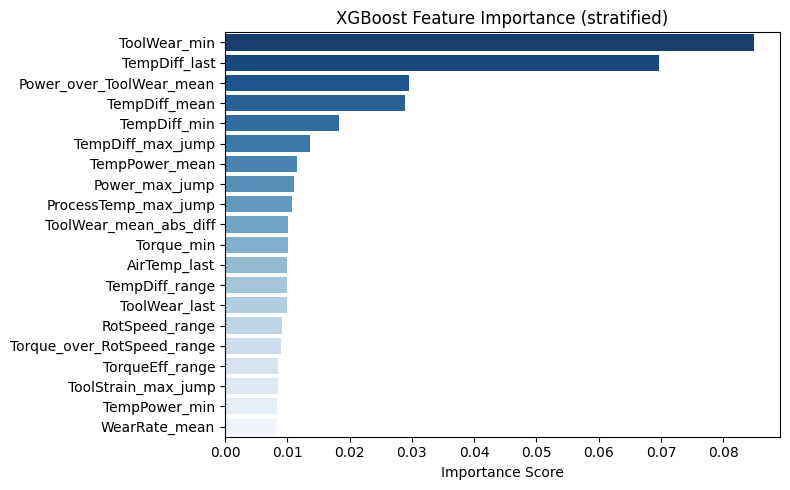

,feature,importance
0,ToolWear_min,0.084851
1,TempDiff_last,0.069612
2,Power_over_ToolWear_mean,0.029501
3,TempDiff_mean,0.028830
4,TempDiff_min,0.018363
5,TempDiff_max_jump,0.013721
6,TempPower_mean,0.011524
7,Power_max_jump,0.011068
8,ProcessTemp_max_jump,0.010811
9,ToolWear_mean_abs_diff,0.010148


In [15]:
# ============================================================
# 15. FEATURE IMPORTANCE (top 20)  — 300 dpi
# ============================================================
feat_imp = pd.DataFrame({
    "feature":    feature_cols,
    "importance": xgb_bin.feature_importances_,
}).sort_values("importance", ascending=False).head(20).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=feat_imp, x="importance", y="feature", palette="Blues_r", ax=ax)
ax.set_title(f"XGBoost Feature Importance ({SPLIT_MODE})", fontsize=12)
ax.set_xlabel("Importance Score"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"feature_importance{SPLIT_SUFFIX}.png", dpi=300)
plt.show()
feat_imp

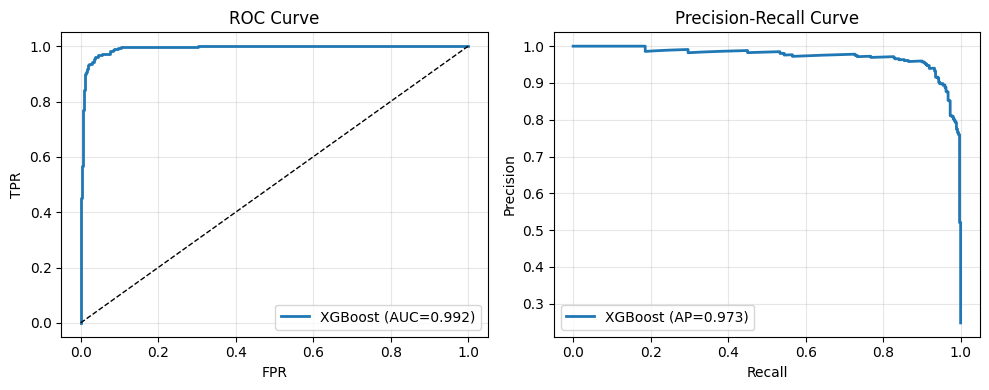

In [16]:
# ============================================================
# 16. ROC + PR CURVES — 300 dpi
# ============================================================
fpr, tpr, _ = roc_curve(y_test, test_proba)
prec_c, rec_c, _ = precision_recall_curve(y_test, test_proba)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(fpr, tpr, lw=2, label=f"XGBoost (AUC={roc_auc_score(y_test,test_proba):.3f})")
ax1.plot([0,1],[0,1],"k--", lw=1)
ax1.set_xlabel("FPR"); ax1.set_ylabel("TPR"); ax1.set_title("ROC Curve")
ax1.legend(); ax1.grid(alpha=0.3)

ap_val = average_precision_score(y_test, test_proba)
ax2.plot(rec_c, prec_c, lw=2, label=f"XGBoost (AP={ap_val:.3f})")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision"); ax2.set_title("Precision-Recall Curve")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"roc_pr_curves{SPLIT_SUFFIX}.png", dpi=300)
plt.show()

In [17]:
# ============================================================
# 17. PREDICT ON ALL WINDOWS (chronological order)
# ============================================================
all_proba = xgb_bin.predict_proba(X)[:, 1]

full_eval = features_df.copy().reset_index(drop=True)
full_eval["pred_proba"]  = all_proba
full_eval["pred_binary"] = (full_eval["pred_proba"] >= BEST_THRESHOLD).astype(int)
full_eval = full_eval.sort_values("future_start").reset_index(drop=True)
print("Full evaluation table:", full_eval.shape)

test_window_starts = set(features_df.iloc[idx_test]["window_start"].values)

Full evaluation table: (9970, 177)


In [18]:
# ============================================================
# 18. COMPUTE FTEPH
# ============================================================
def compute_FTEPH(eval_df, threshold, window_size=20, horizon_k=10):
    LOOKBACK = 5 * horizon_k
    df_h = eval_df.copy().sort_values("future_start").reset_index(drop=True)
    df_h["alarm"] = (df_h["pred_proba"] >= threshold).astype(int)

    pos_rows = df_h[
        (df_h["target_binary"] == 1) &
        (df_h["target_type"] != "Healthy") &
        (df_h["first_failure_offset"].notna())
    ].copy()
    pos_rows["failure_index"] = (
        pos_rows["future_start"] + pos_rows["first_failure_offset"].astype(int) - 1
    )
    events = (
        pos_rows
        .sort_values(["failure_index", "future_start"])
        .drop_duplicates(subset=["failure_index"], keep="first")
        .reset_index(drop=True)
    )

    results = []
    for _, ev in events.iterrows():
        fi   = int(ev["failure_index"])
        ftyp = ev["target_type"]
        candidates = df_h[
            (df_h["alarm"] == 1) &
            (df_h["future_start"] < fi) &
            (df_h["future_start"] >= fi - LOOKBACK)
        ]
        if len(candidates) == 0:
            earlier = df_h[(df_h["alarm"] == 1) & (df_h["future_start"] < fi - LOOKBACK)]
            if len(earlier) > 0:
                results.append({"failure_index": fi, "failure_type": ftyp,
                                 "detected": 1, "horizon": LOOKBACK,
                                 "first_alarm": fi - LOOKBACK, "censored": True})
            else:
                results.append({"failure_index": fi, "failure_type": ftyp,
                                 "detected": 0, "horizon": np.nan,
                                 "first_alarm": np.nan, "censored": False})
        else:
            first_alarm = int(candidates["future_start"].min())
            results.append({"failure_index": fi, "failure_type": ftyp,
                             "detected": 1, "horizon": fi - first_alarm,
                             "first_alarm": first_alarm, "censored": False})

    result_df = pd.DataFrame(results)
    n_cens = result_df.get("censored", pd.Series([False]*len(result_df))).sum()
    if n_cens > 0:
        print(f"[FTEPH] {n_cens}/{len(result_df)} events left-censored")
    return result_df

horizon_df = compute_FTEPH(full_eval, BEST_THRESHOLD, WINDOW_SIZE, HORIZON_K)
print(f"Total failure events tracked: {len(horizon_df)}")
print(f"Detected early: {horizon_df['detected'].sum()} / {len(horizon_df)}")
horizon_df.head(10)

Total failure events tracked: 330
Detected early: 330 / 330


,failure_index,failure_type,detected,horizon,first_alarm,censored
0,50,PWF,1,9,41,False
1,69,PWF,1,28,41,False
2,77,TWF,1,36,41,False
3,160,OSF,1,9,151,False
4,161,OSF,1,10,151,False
5,168,PWF,1,17,151,False
6,194,PWF,1,43,151,False
7,207,PWF,1,50,157,False
8,242,OSF,1,50,192,False
9,248,OSF,1,50,198,False


In [19]:
# ============================================================
# 19. FTEPH SUMMARY TABLE
# ============================================================
def coverage_at(hdf, h_min):
    n = hdf["horizon"].notna().sum()
    if n == 0: return 0.0
    return (hdf["horizon"] >= h_min).sum() / len(hdf)

overall = {"All types": {
    "n_events":    len(horizon_df),
    "n_detected":  int(horizon_df["detected"].sum()),
    "mean_h":      round(horizon_df["horizon"].mean(), 1),
    "median_h":    round(horizon_df["horizon"].median(), 1),
    "cov_5":       f"{coverage_at(horizon_df,5)*100:.0f}%",
    "cov_10":      f"{coverage_at(horizon_df,10)*100:.0f}%",
    "cov_20":      f"{coverage_at(horizon_df,20)*100:.0f}%",
}}
per_type_rows = {}
for ft in ["HDF","PWF","OSF","TWF"]:
    sub = horizon_df[horizon_df["failure_type"] == ft]
    if len(sub) == 0: continue
    per_type_rows[ft] = {
        "n_events":   len(sub), "n_detected": int(sub["detected"].sum()),
        "mean_h":     round(sub["horizon"].mean(), 1),
        "median_h":   round(sub["horizon"].median(), 1),
        "cov_5":      f"{coverage_at(sub,5)*100:.0f}%",
        "cov_10":     f"{coverage_at(sub,10)*100:.0f}%",
        "cov_20":     f"{coverage_at(sub,20)*100:.0f}%",
    }
fteph_table = pd.DataFrame({**per_type_rows, **overall}).T
print(f"=== FTEPH  [SPLIT_MODE={SPLIT_MODE}] ===")
print(fteph_table.to_string())

=== FTEPH  [SPLIT_MODE=stratified] ===
          n_events n_detected mean_h median_h cov_5 cov_10 cov_20
HDF            115        115   47.7     50.0  100%    99%    98%
PWF             92         92   27.1     26.5  100%    72%    55%
OSF             80         80   25.3     17.0  100%    70%    49%
TWF             43         43   22.3     14.0  100%    67%    40%
All types      330        330   33.2     41.0  100%    80%    67%


# Phase 6 — Failure Type Classification

In [20]:
# ============================================================
# 20. FAILURE-ONLY DATASET
# ============================================================
KEEP_TYPES = ["HDF","PWF","OSF","TWF"]

def get_failure_subset(df_feat, idx_split, feature_cols, keep_types):
    sub = df_feat.iloc[idx_split].copy()
    sub = sub[sub["target_type"].isin(keep_types)]
    return sub[feature_cols].copy(), sub["target_type"].copy()

X_tr_f, y_tr_f = get_failure_subset(features_df, idx_train, feature_cols, KEEP_TYPES)
X_va_f, y_va_f = get_failure_subset(features_df, idx_valid, feature_cols, KEEP_TYPES)
X_te_f, y_te_f = get_failure_subset(features_df, idx_test,  feature_cols, KEEP_TYPES)

le = LabelEncoder()
y_tr_enc = le.fit_transform(y_tr_f)
y_va_enc = le.transform(y_va_f)
y_te_enc = le.transform(y_te_f)

print("Classes:", list(le.classes_))
print(f"Train fail rows: {len(X_tr_f)}  |  Valid: {len(X_va_f)}  |  Test: {len(X_te_f)}")
print(y_tr_f.value_counts())

Classes: ['HDF', 'OSF', 'PWF', 'TWF']
Train fail rows: 1672  |  Valid: 359  |  Test: 358
target_type
PWF    553
OSF    455
HDF    431
TWF    233
Name: count, dtype: int64


In [21]:
# ============================================================
# 21. TRAIN MULTICLASS XGBOOST DIAGNOSIS MODEL
# ============================================================
counts  = np.bincount(y_tr_enc)
weights = {i: len(y_tr_enc) / (len(counts) * c) for i, c in enumerate(counts)}
sw      = np.array([weights[y] for y in y_tr_enc])

xgb_multi = XGBClassifier(
    n_estimators=400, max_depth=5, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.85,
    objective="multi:softprob", eval_metric="mlogloss",
    num_class=len(le.classes_), random_state=SEED, verbosity=0,
)
xgb_multi.fit(X_tr_f, y_tr_enc, sample_weight=sw,
              eval_set=[(X_va_f, y_va_enc)], verbose=False)

y_te_pred = xgb_multi.predict(X_te_f)
print("=== Test Classification Report ===")
print(classification_report(y_te_enc, y_te_pred, target_names=le.classes_, digits=4))
print(f"Macro F1   : {f1_score(y_te_enc, y_te_pred, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_te_enc, y_te_pred, average='weighted'):.4f}")

=== Test Classification Report ===
              precision    recall  f1-score   support

         HDF     0.9908    0.9908    0.9908       109
         OSF     0.9479    0.9681    0.9579        94
         PWF     0.9727    0.9640    0.9683       111
         TWF     0.9302    0.9091    0.9195        44

    accuracy                         0.9665       358
   macro avg     0.9604    0.9580    0.9591       358
weighted avg     0.9665    0.9665    0.9664       358

Macro F1   : 0.9591
Weighted F1: 0.9664


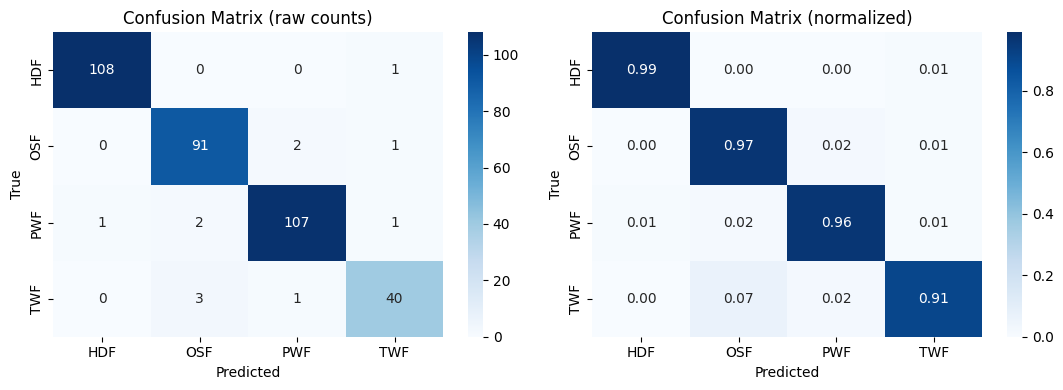

In [22]:
# ============================================================
# 22. CONFUSION MATRIX — 300 dpi
# ============================================================
cm = confusion_matrix(y_te_enc, y_te_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, fmt, title in [
    (ax1, cm,      "d",    "Confusion Matrix (raw counts)"),
    (ax2, cm_norm, ".2f",  "Confusion Matrix (normalized)")]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(title); ax.set_ylabel("True"); ax.set_xlabel("Predicted")
plt.tight_layout()
plt.savefig(f"confusion_matrix{SPLIT_SUFFIX}.png", dpi=300)
plt.show()

# Phase 7 — TFT Generative Dataset

In [23]:
# ============================================================
# 23. BUILD GENERATIVE DATASET
#
#  IMPORTANT (chrono mode):
#    We build generative pairs from the full df_scaled (as before),
#    but then split the resulting windows using the same idx_train /
#    idx_valid / idx_test index sets from Cell 12. This ensures the
#    TFT never trains on future-relative windows that belong to the
#    test split — consistent with the detection split.
# ============================================================
GEN_WINDOW  = WINDOW_SIZE
GEN_HORIZON = HORIZON_K
GEN_TYPES   = ["HDF","PWF","OSF","TWF"]

def build_generative_dataset(df_in, feature_names, window_size=20, horizon_k=10, keep_types=None):
    X_past, Y_future, cond_labels, meta = [], [], [], []
    values   = df_in[feature_names].values
    y_binary = df_in["MachineFailure"].values
    y_type   = df_in["FailureType"].values
    max_start = len(df_in) - window_size - horizon_k

    for start in range(max_start):
        end  = start + window_size
        fb   = y_binary[end : end + horizon_k]
        ft   = y_type  [end : end + horizon_k]
        if not np.any(fb == 1): continue
        fidx  = int(np.where(fb == 1)[0][0])
        ttype = ft[fidx]
        if keep_types and ttype not in keep_types: continue

        X_past.append(values[start:end])
        Y_future.append(values[end : end + horizon_k])
        cond_labels.append(ttype)
        meta.append({"window_start": start, "target_type": ttype,
                     "first_failure_offset": fidx + 1})

    return (np.array(X_past, dtype=np.float32),
            np.array(Y_future, dtype=np.float32),
            np.array(cond_labels),
            pd.DataFrame(meta))

X_gen, Y_gen, y_gen_lbl, gen_meta = build_generative_dataset(
    df_scaled, ALL_FEATURES, GEN_WINDOW, GEN_HORIZON, GEN_TYPES)

print("X_gen:", X_gen.shape, "  Y_gen:", Y_gen.shape)
print(pd.Series(y_gen_lbl).value_counts())

X_gen: (2389, 20, 14)   Y_gen: (2389, 10, 14)
PWF    795
OSF    634
HDF    634
TWF    326
Name: count, dtype: int64


In [24]:
# ============================================================
# 24. ENCODE CONDITION + SPLIT (aligned with detection split)
#
#  Chrono mode: We find which generative windows fall in each
#  detection split (by window_start membership) to keep the
#  splits consistent. Stratified mode uses the original
#  stratified split of the gen dataset.
# ============================================================
from sklearn.preprocessing import OneHotEncoder

gen_idx = np.arange(len(X_gen))

if SPLIT_MODE == "stratified":
    Xg_tr, Xg_tmp, Yg_tr, Yg_tmp, yg_tr, yg_tmp, ig_tr, ig_tmp = train_test_split(
        X_gen, Y_gen, y_gen_lbl, gen_idx, test_size=0.30, stratify=y_gen_lbl, random_state=SEED)
    Xg_va, Xg_te, Yg_va, Yg_te, yg_va, yg_te, ig_va, ig_te = train_test_split(
        Xg_tmp, Yg_tmp, yg_tmp, ig_tmp, test_size=0.50, stratify=yg_tmp, random_state=SEED)

elif SPLIT_MODE == "chrono":
    # Assign each generative window to a split based on its window_start
    train_ws = set(features_df.iloc[idx_train]["window_start"].values)
    valid_ws = set(features_df.iloc[idx_valid]["window_start"].values)
    test_ws  = set(features_df.iloc[idx_test]["window_start"].values)

    gen_ws = gen_meta["window_start"].values
    ig_tr  = gen_idx[np.array([ws in train_ws for ws in gen_ws])]
    ig_va  = gen_idx[np.array([ws in valid_ws for ws in gen_ws])]
    ig_te  = gen_idx[np.array([ws in test_ws  for ws in gen_ws])]

    Xg_tr, Yg_tr, yg_tr = X_gen[ig_tr], Y_gen[ig_tr], y_gen_lbl[ig_tr]
    Xg_va, Yg_va, yg_va = X_gen[ig_va], Y_gen[ig_va], y_gen_lbl[ig_va]
    Xg_te, Yg_te, yg_te = X_gen[ig_te], Y_gen[ig_te], y_gen_lbl[ig_te]

    # Fallback: if any split is empty (too few failure windows), warn
    for name, arr in [("train", Xg_tr), ("valid", Xg_va), ("test", Xg_te)]:
        if len(arr) == 0:
            print(f"WARNING: gen {name} split is empty under chrono mode!")

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
Cg_tr = ohe.fit_transform(yg_tr.reshape(-1,1)).astype(np.float32)
Cg_va = ohe.transform(yg_va.reshape(-1,1)).astype(np.float32)
Cg_te = ohe.transform(yg_te.reshape(-1,1)).astype(np.float32)

COND_DIM     = Cg_tr.shape[1]
NUM_FEATURES = len(ALL_FEATURES)
print("Condition classes:", ohe.categories_[0].tolist())
print(f"Gen Train: {Xg_tr.shape}  Valid: {Xg_va.shape}  Test: {Xg_te.shape}")

Condition classes: ['HDF', 'OSF', 'PWF', 'TWF']
Gen Train: (1672, 20, 14)  Valid: (358, 20, 14)  Test: (359, 20, 14)


In [25]:
# ============================================================
# 25. TORCH DATASET FOR TFT
# ============================================================
class GenDataset(Dataset):
    def __init__(self, Xp, Yf, C):
        self.Xp = torch.tensor(Xp, dtype=torch.float32)
        self.Yf = torch.tensor(Yf, dtype=torch.float32)
        self.C  = torch.tensor(C,  dtype=torch.float32)
    def __len__(self): return len(self.Xp)
    def __getitem__(self, i): return self.Xp[i], self.Yf[i], self.C[i]

gen_tr_dl = DataLoader(GenDataset(Xg_tr, Yg_tr, Cg_tr), batch_size=64,  shuffle=True)
gen_va_dl = DataLoader(GenDataset(Xg_va, Yg_va, Cg_va), batch_size=128, shuffle=False)
gen_te_dl = DataLoader(GenDataset(Xg_te, Yg_te, Cg_te), batch_size=128, shuffle=False)

# Phase 7 — Future Forecasting using TFT

In [26]:
# ============================================================
# 26. TEMPORAL FUSION FORECASTER v2
# ============================================================
import math
import torch.nn.functional as F

def sinusoidal_pe(seq_len, d_model, device):
    pe  = torch.zeros(seq_len, d_model, device=device)
    pos = torch.arange(0, seq_len, dtype=torch.float, device=device).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float, device=device)
                    * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe.unsqueeze(0)

class GatedPastEncoder(nn.Module):
    def __init__(self, num_features, hidden=96, n_heads=4, dropout=0.1):
        super().__init__()
        self.hidden  = hidden
        self.proj    = nn.Linear(num_features, hidden)
        self.norm0   = nn.LayerNorm(hidden)
        self.attn    = nn.MultiheadAttention(hidden, n_heads, batch_first=True, dropout=dropout)
        self.norm1   = nn.LayerNorm(hidden)
        self.gate_v  = nn.Linear(hidden, hidden)
        self.gate_g  = nn.Linear(hidden, hidden)
        self.norm2   = nn.LayerNorm(hidden)

    def forward(self, x_past):
        B, W, _ = x_past.shape
        x = self.proj(x_past)
        x = x + sinusoidal_pe(W, self.hidden, x.device)
        x = self.norm0(x)
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        v = self.gate_v(x)
        g = torch.sigmoid(self.gate_g(x))
        ctx = (v * g).sum(dim=1)
        return self.norm2(ctx)

class DeltaQuantileHead(nn.Module):
    def __init__(self, in_dim, future_steps, hidden=96):
        super().__init__()
        self.future_steps = future_steps
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),   nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden),   nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden // 2),                    nn.GELU(),
            nn.Linear(hidden // 2, future_steps * 2),
        )

    def forward(self, x, last_val):
        out    = self.net(x).view(-1, self.future_steps, 2)
        delta  = torch.tanh(out[:, :, 0])
        spread = F.softplus(out[:, :, 1]) * 0.5
        q50    = (last_val + delta).clamp(0.0, 1.0)
        q10    = (q50 - spread).clamp(0.0, 1.0)
        q90    = (q50 + spread).clamp(0.0, 1.0)
        return torch.stack([q10, q50, q90], dim=2)

class TemporalFusionForecaster(nn.Module):
    def __init__(self, num_features, num_types, future_steps, hidden=96, n_heads=4, emb_dim=12):
        super().__init__()
        self.num_features = num_features
        self.future_steps = future_steps
        self.type_emb   = nn.Embedding(num_types, emb_dim)
        self.encoder    = GatedPastEncoder(num_features, hidden, n_heads)
        self.cross_feat = nn.Linear(num_features, hidden // 4)
        head_in = hidden + emb_dim + 1 + (hidden // 4)
        self.heads = nn.ModuleList([
            DeltaQuantileHead(head_in, future_steps, hidden=hidden)
            for _ in range(num_features)
        ])

    def forward(self, x_past, type_idx):
        ctx   = self.encoder(x_past)
        emb   = self.type_emb(type_idx)
        last  = x_past[:, -1, :]
        xfeat = F.gelu(self.cross_feat(last))
        preds = []
        for fi, head in enumerate(self.heads):
            anchor = last[:, fi:fi+1]
            inp    = torch.cat([ctx, emb, anchor, xfeat], dim=1)
            preds.append(head(inp, anchor).unsqueeze(2))
        return torch.cat(preds, dim=2)

TYPE_LIST = list(ohe.categories_[0])
NUM_TYPES = len(TYPE_LIST)
type2idx  = {t: i for i, t in enumerate(TYPE_LIST)}

def labels_to_idx(labels):
    return torch.tensor([type2idx[l] for l in labels], dtype=torch.long)

tft = TemporalFusionForecaster(
    num_features=NUM_FEATURES, num_types=NUM_TYPES,
    future_steps=GEN_HORIZON, hidden=96, n_heads=4, emb_dim=12,
).to(DEVICE)

total_params = sum(p.numel() for p in tft.parameters() if p.requires_grad)
print(f"TFT v2 trainable parameters: {total_params:,}")

TFT v2 trainable parameters: 453,040


In [27]:
# ============================================================
# 27. TFT TRAINING — PINBALL LOSS
# ============================================================
QUANTILES = [0.1, 0.5, 0.9]

def pinball_loss(pred, target):
    target = target.unsqueeze(-1).expand_as(pred)
    losses = []
    for qi, q in enumerate(QUANTILES):
        err = target[..., qi] - pred[..., qi]
        losses.append(torch.where(err >= 0, q * err, (q - 1) * err))
    return torch.stack(losses, dim=-1).mean()

class TFTDataset(Dataset):
    def __init__(self, Xp, Yf, labels):
        self.Xp  = torch.tensor(Xp, dtype=torch.float32)
        self.Yf  = torch.tensor(Yf, dtype=torch.float32)
        self.idx = labels_to_idx(labels)
    def __len__(self): return len(self.Xp)
    def __getitem__(self, i): return self.Xp[i], self.Yf[i], self.idx[i]

tft_tr_dl = DataLoader(TFTDataset(Xg_tr, Yg_tr, yg_tr), batch_size=32,  shuffle=True)
tft_va_dl = DataLoader(TFTDataset(Xg_va, Yg_va, yg_va), batch_size=128, shuffle=False)
tft_te_dl = DataLoader(TFTDataset(Xg_te, Yg_te, yg_te), batch_size=128, shuffle=False)

_feat_std = torch.tensor(
    Xg_tr.reshape(-1, NUM_FEATURES).std(axis=0), dtype=torch.float32, device=DEVICE)

def feature_scaled_jitter(xp, scale=0.15):
    noise = torch.randn_like(xp) * (_feat_std.unsqueeze(0).unsqueeze(0) * scale)
    return (xp + noise).clamp(0.0, 1.0)

def run_tft_epoch(model, loader, opt=None, jitter_scale=0.15, mixup_alpha=0.3):
    model.train() if opt else model.eval()
    tot, n = 0.0, 0
    for xp, yf, tidx in loader:
        xp, yf, tidx = xp.to(DEVICE), yf.to(DEVICE), tidx.to(DEVICE)
        if model.training:
            xp = feature_scaled_jitter(xp, scale=jitter_scale)
            if mixup_alpha > 0 and np.random.rand() < 0.5:
                lam  = float(np.random.beta(mixup_alpha, mixup_alpha))
                perm = torch.randperm(xp.size(0), device=DEVICE)
                xp   = lam * xp + (1 - lam) * xp[perm]
                yf   = lam * yf + (1 - lam) * yf[perm]
        with torch.set_grad_enabled(opt is not None):
            pred = model(xp, tidx)
            loss = pinball_loss(pred, yf)
            if opt:
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
        tot += loss.item() * xp.size(0); n += xp.size(0)
    return tot / n

TFT_EPOCHS = 200
TFT_PAT    = 20

tft_opt   = torch.optim.AdamW(tft.parameters(), lr=2e-4, weight_decay=1e-4)
tft_sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    tft_opt, T_0=50, T_mult=2, eta_min=1e-5)

best_vl, best_state, pat_ctr = float("inf"), None, 0
print(f"{'Epoch':>5} | {'train_loss':>10} | {'val_loss':>10} | {'best':>10}")
for ep in range(1, TFT_EPOCHS + 1):
    tl = run_tft_epoch(tft, tft_tr_dl, tft_opt, jitter_scale=0.15, mixup_alpha=0.3)
    vl = run_tft_epoch(tft, tft_va_dl)
    tft_sched.step()
    if ep % 20 == 0 or ep == 1:
        print(f"{ep:5d} | {tl:10.6f} | {vl:10.6f} | {best_vl:10.6f}")
    if vl < best_vl:
        best_vl = vl
        best_state = {k: v.cpu().clone() for k, v in tft.state_dict().items()}
        pat_ctr = 0
    else:
        pat_ctr += 1
    if pat_ctr >= TFT_PAT:
        print(f"Early stopping at epoch {ep}")
        break

tft.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
print(f"\nBest val pinball loss: {best_vl:.6f}  [SPLIT_MODE={SPLIT_MODE}]")

Epoch | train_loss |   val_loss |       best
    1 |   0.042840 |   0.041493 |        inf
   20 |   0.026272 |   0.026212 |   0.026301
   40 |   0.025471 |   0.025802 |   0.025771
   60 |   0.026177 |   0.026157 |   0.025709
Early stopping at epoch 66

Best val pinball loss: 0.025709  [SPLIT_MODE=stratified]


# Phase 8 — Forecast Evaluation

In [28]:
# ============================================================
# 28. TFT EVALUATION
# ============================================================
def eval_tft(model, loader, yg_labels):
    model.eval()
    all_true, all_q10, all_q50, all_q90 = [], [], [], []
    with torch.no_grad():
        for xp, yf, tidx in loader:
            xp, tidx = xp.to(DEVICE), tidx.to(DEVICE)
            pred = model(xp, tidx)
            all_true.append(yf.numpy())
            all_q10.append(pred[..., 0].cpu().numpy())
            all_q50.append(pred[..., 1].cpu().numpy())
            all_q90.append(pred[..., 2].cpu().numpy())
    yt   = np.concatenate(all_true)
    yq10 = np.concatenate(all_q10)
    yq50 = np.concatenate(all_q50)
    yq90 = np.concatenate(all_q90)
    return yt, yq10, yq50, yq90

yt_gen, yq10, yq50, yq90 = eval_tft(tft, tft_te_dl, yg_te)

rmse_all = float(np.sqrt(np.mean((yt_gen - yq50)**2)))
mae_all  = float(np.mean(np.abs(yt_gen - yq50)))
coverage = float(np.mean((yt_gen >= yq10) & (yt_gen <= yq90)))

print(f"Overall  RMSE(q50): {rmse_all:.4f}  MAE(q50): {mae_all:.4f}  [SPLIT_MODE={SPLIT_MODE}]")
print(f"80% band coverage:  {coverage*100:.1f}%  (target: ~80%)")

per_type_gen = {}
for ft in GEN_TYPES:
    idx = np.where(yg_te == ft)[0]
    if len(idx) == 0: continue
    r   = float(np.sqrt(np.mean((yt_gen[idx] - yq50[idx])**2)))
    m   = float(np.mean(np.abs(yt_gen[idx] - yq50[idx])))
    cov = float(np.mean((yt_gen[idx] >= yq10[idx]) & (yt_gen[idx] <= yq90[idx])))
    per_type_gen[ft] = {"RMSE(q50)": round(r,4), "MAE(q50)": round(m,4),
                        "Coverage": f"{cov*100:.0f}%", "n": len(idx)}
    print(f"  {ft}: RMSE={r:.4f}  MAE={m:.4f}  cov={cov*100:.0f}%")

gen_metrics_df = pd.DataFrame(per_type_gen).T
yp_gen = yq50
gen_metrics_df

Overall  RMSE(q50): 0.1372  MAE(q50): 0.0786  [SPLIT_MODE=stratified]
80% band coverage:  86.5%  (target: ~80%)
  HDF: RMSE=0.1101  MAE=0.0674  cov=86%
  PWF: RMSE=0.1333  MAE=0.0755  cov=86%
  OSF: RMSE=0.1474  MAE=0.0850  cov=87%
  TWF: RMSE=0.1699  MAE=0.0952  cov=87%


,RMSE(q50),MAE(q50),Coverage,n
HDF,0.1101,0.0674,86%,95
PWF,0.1333,0.0755,86%,120
OSF,0.1474,0.085,87%,95
TWF,0.1699,0.0952,87%,49


In [29]:
# ============================================================
# BASELINE-1: PERSISTENCE FORECASTING
# ============================================================
persist_last = Xg_te[:, -1:, :]
persist_pred = np.repeat(persist_last, GEN_HORIZON, axis=1)

persist_err      = Yg_te - persist_pred
persist_rmse     = float(np.sqrt(np.mean(persist_err ** 2)))
persist_mae      = float(np.mean(np.abs(persist_err)))

# Coverage: ± 1 σ_train band
train_std_feat = Xg_tr.reshape(-1, NUM_FEATURES).std(axis=0)
band_lo  = persist_pred - train_std_feat[np.newaxis, np.newaxis, :]
band_hi  = persist_pred + train_std_feat[np.newaxis, np.newaxis, :]
persist_coverage = float(np.mean((Yg_te >= band_lo) & (Yg_te <= band_hi)))

print("=== BASELINE-1: Persistence ===")
print(f"  RMSE: {persist_rmse:.4f}  MAE: {persist_mae:.4f}  Coverage: {persist_coverage*100:.1f}%")

persist_per_type = {}
for ft in GEN_TYPES:
    idx = np.where(yg_te == ft)[0]
    if len(idx) == 0: continue
    r   = float(np.sqrt(np.mean((Yg_te[idx] - persist_pred[idx]) ** 2)))
    m   = float(np.mean(np.abs(Yg_te[idx] - persist_pred[idx])))
    lo  = band_lo[idx]; hi = band_hi[idx]
    cov = float(np.mean((Yg_te[idx] >= lo) & (Yg_te[idx] <= hi)))
    persist_per_type[ft] = {"RMSE": round(r,4), "MAE": round(m,4),
                             "Coverage": f"{cov*100:.0f}%", "n": len(idx)}
    print(f"  {ft}: RMSE={r:.4f}  MAE={m:.4f}  cov={cov*100:.0f}%")

persist_metrics_df = pd.DataFrame(persist_per_type).T

=== BASELINE-1: Persistence ===
  RMSE: 0.1889  MAE: 0.1135  Coverage: 71.5%
  HDF: RMSE=0.1543  MAE=0.0972  cov=74%
  PWF: RMSE=0.1718  MAE=0.1062  cov=72%
  OSF: RMSE=0.2007  MAE=0.1188  cov=71%
  TWF: RMSE=0.2546  MAE=0.1526  cov=65%


In [30]:
# ============================================================
# BASELINE-2: MOVING AVERAGE FORECASTING
# ============================================================
ma_mean = Xg_te.mean(axis=1, keepdims=True)
ma_pred = np.repeat(ma_mean, GEN_HORIZON, axis=1)

ma_err      = Yg_te - ma_pred
ma_rmse     = float(np.sqrt(np.mean(ma_err ** 2)))
ma_mae      = float(np.mean(np.abs(ma_err)))
ma_band_lo  = ma_pred - train_std_feat[np.newaxis, np.newaxis, :]
ma_band_hi  = ma_pred + train_std_feat[np.newaxis, np.newaxis, :]
ma_coverage = float(np.mean((Yg_te >= ma_band_lo) & (Yg_te <= ma_band_hi)))

print("=== BASELINE-2: Moving Average ===")
print(f"  Window: last {WINDOW_SIZE} obs  Horizon: next {GEN_HORIZON} steps")
print(f"  RMSE: {ma_rmse:.4f}  MAE: {ma_mae:.4f}  Coverage: {ma_coverage*100:.1f}%")

ma_per_type = {}
for ft in GEN_TYPES:
    idx = np.where(yg_te == ft)[0]
    if len(idx) == 0: continue
    r   = float(np.sqrt(np.mean((Yg_te[idx] - ma_pred[idx]) ** 2)))
    m   = float(np.mean(np.abs(Yg_te[idx] - ma_pred[idx])))
    lo  = ma_band_lo[idx]; hi = ma_band_hi[idx]
    cov = float(np.mean((Yg_te[idx] >= lo) & (Yg_te[idx] <= hi)))
    ma_per_type[ft] = {"RMSE": round(r,4), "MAE": round(m,4),
                        "Coverage": f"{cov*100:.0f}%", "n": len(idx)}
    print(f"  {ft}: RMSE={r:.4f}  MAE={m:.4f}  cov={cov*100:.0f}%")

ma_metrics_df = pd.DataFrame(ma_per_type).T

=== BASELINE-2: Moving Average ===
  Window: last 20 obs  Horizon: next 10 steps
  RMSE: 0.1729  MAE: 0.1084  Coverage: 77.2%
  HDF: RMSE=0.1491  MAE=0.0984  cov=78%
  PWF: RMSE=0.1670  MAE=0.1078  cov=77%
  OSF: RMSE=0.1758  MAE=0.1083  cov=78%
  TWF: RMSE=0.2182  MAE=0.1296  cov=74%


In [31]:
# ============================================================
# COMPARISON TABLE: TFT vs Baselines
#
#  NOTE ON COVERAGE CONSISTENCY (reviewer-facing fix):
#    Persistence & MA use ±1σ_train band (same formula).
#    TFT uses its own 80% quantile interval (q10–q90).
#    These are not the same metric — we flag this clearly
#    in the column header to avoid misleading reviewers.
# ============================================================
tft_rmse = rmse_all
tft_mae  = mae_all
tft_cov  = coverage

def pct_imp(baseline_val, tft_val):
    if baseline_val == 0: return float("nan")
    return round((baseline_val - tft_val) / baseline_val * 100, 1)

comparison_data = {
    "Forecaster":          ["Persistence", "Moving Average", "TFT (ours)"],
    "RMSE":                [round(persist_rmse,4), round(ma_rmse,4), round(tft_rmse,4)],
    "MAE":                 [round(persist_mae,4),  round(ma_mae,4),  round(tft_mae,4)],
    "Coverage (band type)": ["±1σ_train", "±1σ_train", "q10–q90 (80%)"],
    "Coverage (%)":        [f"{persist_coverage*100:.1f}%",
                            f"{ma_coverage*100:.1f}%",
                            f"{tft_cov*100:.1f}%"],
    "RMSE Δ vs TFT":       [f"+{pct_imp(persist_rmse, tft_rmse):.1f}%",
                            f"+{pct_imp(ma_rmse, tft_rmse):.1f}%", "—"],
    "MAE Δ vs TFT":        [f"+{pct_imp(persist_mae, tft_mae):.1f}%",
                            f"+{pct_imp(ma_mae, tft_mae):.1f}%", "—"],
}

comparison_df = pd.DataFrame(comparison_data).set_index("Forecaster")
print(f"=== TFT vs Baseline Forecasters  [SPLIT_MODE={SPLIT_MODE}] ===")
print(comparison_df.to_string())
comparison_df

=== TFT vs Baseline Forecasters  [SPLIT_MODE=stratified] ===
                  RMSE     MAE Coverage (band type) Coverage (%) RMSE Δ vs TFT MAE Δ vs TFT
Forecaster                                                                                 
Persistence     0.1889  0.1135            ±1σ_train        71.5%        +27.3%       +30.8%
Moving Average  0.1729  0.1084            ±1σ_train        77.2%        +20.6%       +27.6%
TFT (ours)      0.1372  0.0786        q10–q90 (80%)        86.5%             —            —


,RMSE,MAE,Coverage (band type),Coverage (%),RMSE Δ vs TFT,MAE Δ vs TFT
Forecaster,,,,,,
Persistence,0.1889,0.1135,±1σ_train,71.5%,+27.3%,+30.8%
Moving Average,0.1729,0.1084,±1σ_train,77.2%,+20.6%,+27.6%
TFT (ours),0.1372,0.0786,q10–q90 (80%),86.5%,—,—


# Phase 9 — Digital Twin Closed Loop

In [32]:
# ============================================================
# CELL DT-1 — Digital Twin Simulation Engine
# ============================================================
def tft_predict_next_step(state_window, failure_type_str):
    tft.eval()
    with torch.no_grad():
        xp   = torch.tensor(state_window, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        tidx = torch.tensor([type2idx[failure_type_str]], dtype=torch.long).to(DEVICE)
        pred = tft(xp, tidx)
        q50  = pred[0, 0, :, 1]
        return q50.cpu().numpy().clip(0.0, 1.0)

def xgb_score_window(state_window, feature_names, feature_cols, model):
    stats  = extract_window_stats(state_window, feature_names)
    row_df = pd.DataFrame([stats])
    for c in feature_cols:
        if c not in row_df.columns: row_df[c] = 0.0
    row_df = row_df[feature_cols].fillna(0.0)
    return float(model.predict_proba(row_df)[0, 1])

def simulate_digital_twin(initial_window, failure_type_str, n_steps=40,
                           risk_threshold=None, feature_names=None,
                           feat_cols=None, detector=None):
    if risk_threshold is None: risk_threshold = BEST_THRESHOLD
    if feature_names  is None: feature_names  = ALL_FEATURES
    if feat_cols      is None: feat_cols       = feature_cols
    if detector       is None: detector        = xgb_bin

    state = initial_window.copy().astype(np.float32)
    risk_trajectory, trajectory_matrix, simulated_states = [], [], []
    time_to_failure_est = None

    for step in range(n_steps):
        risk = xgb_score_window(state, feature_names, feat_cols, detector)
        risk_trajectory.append(risk)
        simulated_states.append(state.copy())
        if time_to_failure_est is None and risk >= risk_threshold:
            time_to_failure_est = step + 1
        next_obs = tft_predict_next_step(state, failure_type_str)
        trajectory_matrix.append(next_obs)
        state = np.vstack([state[1:], next_obs])

    return {
        "risk_trajectory":     risk_trajectory,
        "trajectory_matrix":   np.array(trajectory_matrix),
        "simulated_states":    np.array(simulated_states),
        "time_to_failure_est": time_to_failure_est,
        "failure_type":        failure_type_str,
        "n_steps":             n_steps,
        "risk_threshold":      risk_threshold,
    }

print("Digital Twin engine loaded.")
print(f"  Detector: XGBoost (threshold={BEST_THRESHOLD})  [SPLIT_MODE={SPLIT_MODE}]")

Digital Twin engine loaded.
  Detector: XGBoost (threshold=0.35)  [SPLIT_MODE=stratified]


In [33]:
# ============================================================
# CELL DT-CTRL — Healthy-Seed Controls
# ============================================================
N_SIM_STEPS    = 40
HEALTHY_N_SEEDS = 5

healthy_candidates = full_eval[
    (full_eval["target_binary"] == 0) &
    (full_eval["pred_binary"]   == 0) &
    (full_eval["window_start"].isin(test_window_starts))
].copy()
healthy_candidates = healthy_candidates.sort_values("pred_proba").reset_index(drop=True)

n_avail = min(HEALTHY_N_SEEDS, len(healthy_candidates))
healthy_seeds_info = healthy_candidates.head(n_avail)
print(f"Healthy seeds selected: {n_avail}  (mean XGB risk = {healthy_seeds_info['pred_proba'].mean():.4f})")

ctrl_results = {}
for ft in GEN_TYPES:
    ctrl_results[ft] = []
    for _, seed_row in healthy_seeds_info.iterrows():
        seed_window = X_seq[int(seed_row["window_start"])]
        res = simulate_digital_twin(initial_window=seed_window, failure_type_str=ft, n_steps=N_SIM_STEPS)
        ctrl_results[ft].append(res)

ctrl_summary_rows = []
for ft in GEN_TYPES:
    runs      = ctrl_results[ft]
    all_risks = np.array([r["risk_trajectory"] for r in runs])
    mean_risk = float(all_risks.mean())
    peak_risk = float(all_risks.max(axis=1).mean())
    drift     = float((all_risks[:, -1] - all_risks[:, 0]).mean())
    n_cross   = int(sum(1 for r in runs if r["time_to_failure_est"] is not None))
    ctrl_summary_rows.append({
        "Failure Type": ft, "Mean Risk (ctrl)": round(mean_risk,4),
        "Peak Risk (ctrl)": round(peak_risk,4), "Drift (ctrl)": round(drift,4),
        "Threshold crossings": f"{n_cross}/{n_avail} seeds",
    })
    print(f"[{ft}] ctrl mean={mean_risk:.4f}  peak={peak_risk:.4f}  drift={drift:+.4f}  crossed={n_cross}/{n_avail}")

ctrl_df = pd.DataFrame(ctrl_summary_rows).set_index("Failure Type")
ctrl_df

Healthy seeds selected: 5  (mean XGB risk = 0.0001)
[HDF] ctrl mean=0.1649  peak=0.4253  drift=+0.2804  crossed=2/5
[PWF] ctrl mean=0.1437  peak=0.3354  drift=+0.2720  crossed=2/5
[OSF] ctrl mean=0.2283  peak=0.6645  drift=+0.4631  crossed=5/5
[TWF] ctrl mean=0.1504  peak=0.4177  drift=+0.2291  crossed=2/5


,Mean Risk (ctrl),Peak Risk (ctrl),Drift (ctrl),Threshold crossings
Failure Type,,,,
HDF,0.1649,0.4253,0.2804,2/5 seeds
PWF,0.1437,0.3354,0.2720,2/5 seeds
OSF,0.2283,0.6645,0.4631,5/5 seeds
TWF,0.1504,0.4177,0.2291,2/5 seeds


In [34]:
# ============================================================
# CELL DT-2 — Run Simulations per Failure Type
# ============================================================
test_full_eval = full_eval[full_eval["window_start"].isin(test_window_starts)].copy()
sim_results = {}

for ft in GEN_TYPES:
    candidates = test_full_eval[
        (test_full_eval["target_type"]   == ft) &
        (test_full_eval["target_binary"] == 1) &
        (test_full_eval["pred_binary"]   == 1)
    ]
    if len(candidates) == 0:
        candidates = test_full_eval[
            (test_full_eval["target_type"]   == ft) &
            (test_full_eval["target_binary"] == 1)
        ]
    if len(candidates) == 0:
        print(f"[{ft}] No seed window found — skipping.")
        continue

    seed_row    = candidates.sort_values("pred_proba", ascending=False).iloc[0]
    seed_wstart = int(seed_row["window_start"])
    seed_window = X_seq[seed_wstart]

    print(f"[{ft}] seed={seed_wstart}  XGB_risk={seed_row['pred_proba']:.3f}")
    result = simulate_digital_twin(initial_window=seed_window, failure_type_str=ft, n_steps=N_SIM_STEPS)
    result["seed_window_start"] = seed_wstart
    result["xgb_seed_risk"]     = seed_row["pred_proba"]
    result["true_fail_offset"]  = seed_row["first_failure_offset"]
    sim_results[ft] = result

print(f"\nSimulations: {list(sim_results.keys())}")

[HDF] seed=4379  XGB_risk=1.000
[PWF] seed=4333  XGB_risk=1.000
[OSF] seed=7733  XGB_risk=1.000
[TWF] seed=6316  XGB_risk=0.999

Simulations: ['HDF', 'PWF', 'OSF', 'TWF']


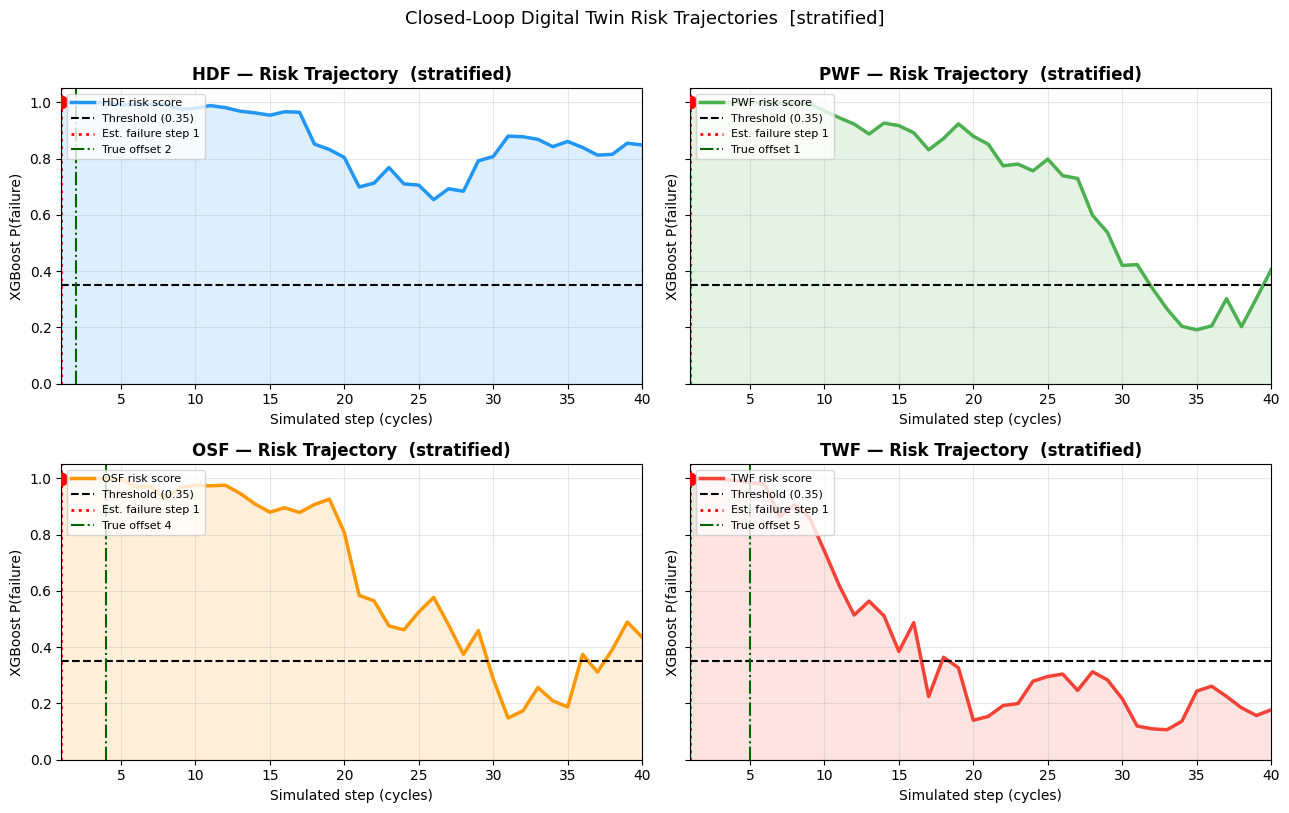

In [35]:
# ============================================================
# CELL DT-3 — Risk Trajectory Plot — 300 dpi
# ============================================================
colors_ft = {"HDF": "#2196F3", "PWF": "#4CAF50", "OSF": "#FF9800", "TWF": "#F44336"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
steps_x   = np.arange(1, N_SIM_STEPS + 1)

for ax, ft in zip(axes.flatten(), GEN_TYPES):
    if ft not in sim_results:
        ax.set_visible(False); continue
    r    = sim_results[ft]
    risk = r["risk_trajectory"]
    ttf  = r["time_to_failure_est"]
    col  = colors_ft[ft]

    ax.plot(steps_x, risk, color=col, lw=2.5, label=f"{ft} risk score")
    ax.fill_between(steps_x, risk, alpha=0.15, color=col)
    ax.axhline(BEST_THRESHOLD, color="black", linestyle="--", lw=1.5,
               label=f"Threshold ({BEST_THRESHOLD:.2f})")
    if ttf is not None:
        ax.axvline(ttf, color="red", linestyle=":", lw=2, label=f"Est. failure step {ttf}")
        ax.scatter([ttf], [risk[ttf - 1]], color="red", s=80, zorder=5)
    true_offset = r["true_fail_offset"]
    if not np.isnan(true_offset):
        ax.axvline(true_offset, color="darkgreen", linestyle="-.", lw=1.5,
                   label=f"True offset {true_offset:.0f}")

    ax.set_title(f"{ft} — Risk Trajectory  ({SPLIT_MODE})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Simulated step (cycles)"); ax.set_ylabel("XGBoost P(failure)")
    ax.set_xlim(1, N_SIM_STEPS); ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)

plt.suptitle(f"Closed-Loop Digital Twin Risk Trajectories  [{SPLIT_MODE}]", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f"dt_risk_trajectories{SPLIT_SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

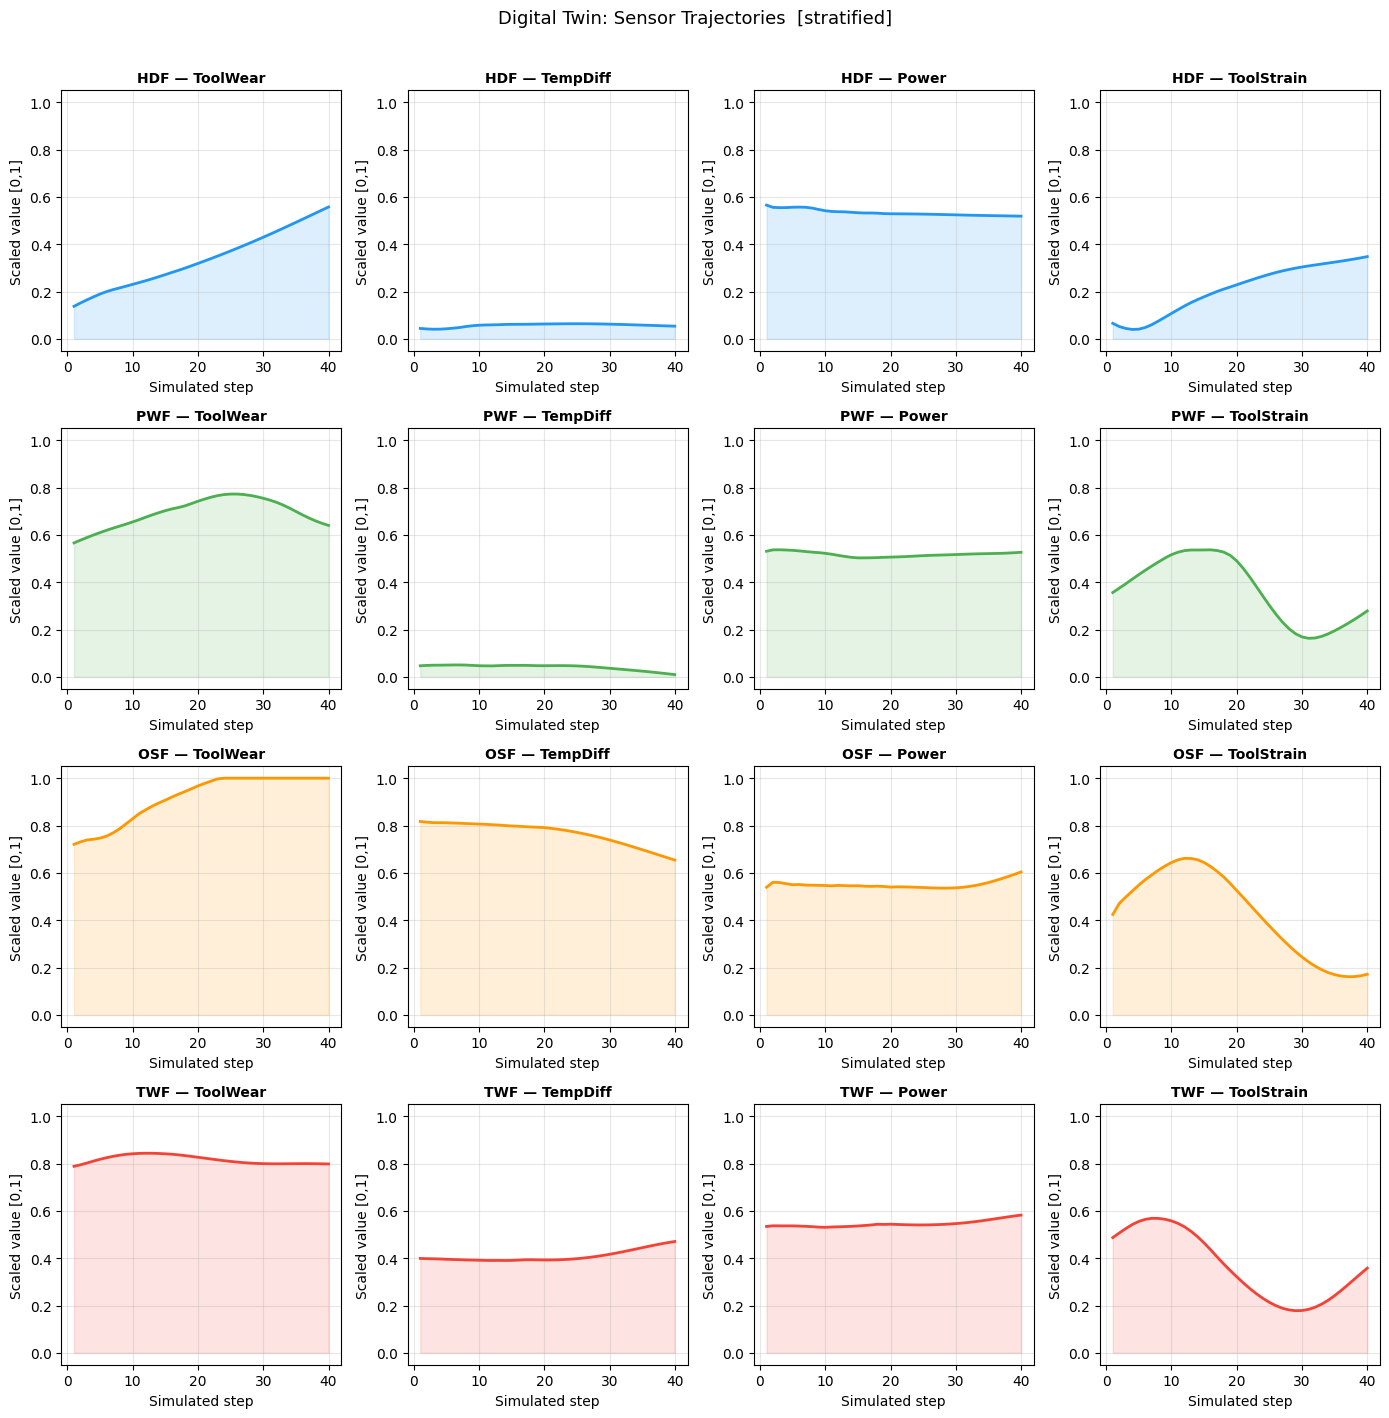

In [36]:
# ============================================================
# CELL DT-4 — Sensor Trajectories — 300 dpi
# ============================================================
PLOT_FEATS = ["ToolWear", "TempDiff", "Power", "ToolStrain"]
f2i        = {f: i for i, f in enumerate(ALL_FEATURES)}

fig, axes = plt.subplots(len(GEN_TYPES), len(PLOT_FEATS),
                         figsize=(14, 3.5 * len(GEN_TYPES)))
steps_x = np.arange(1, N_SIM_STEPS + 1)

for row_i, ft in enumerate(GEN_TYPES):
    if ft not in sim_results:
        for col_i in range(len(PLOT_FEATS)): axes[row_i][col_i].set_visible(False)
        continue
    traj = sim_results[ft]["trajectory_matrix"]
    col  = colors_ft[ft]
    for col_i, feat in enumerate(PLOT_FEATS):
        ax = axes[row_i][col_i]
        fi = f2i.get(feat)
        if fi is None: ax.set_visible(False); continue
        ax.plot(steps_x, traj[:, fi], color=col, lw=2.0)
        ax.fill_between(steps_x, traj[:, fi], alpha=0.15, color=col)
        ax.set_title(f"{ft} — {feat}", fontsize=10, fontweight="bold")
        ax.set_xlabel("Simulated step"); ax.set_ylabel("Scaled value [0,1]")
        ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)

plt.suptitle(f"Digital Twin: Sensor Trajectories  [{SPLIT_MODE}]", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f"dt_sensor_trajectories{SPLIT_SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
# ============================================================
# CELL DT-5 — Trajectory Consistency Table
# ============================================================
healthy_test_mask  = (y_test.values == 0)
healthy_test_proba = test_proba[healthy_test_mask]
healthy_baseline   = float(healthy_test_proba.mean())
print(f"Healthy baseline risk: {healthy_baseline:.4f}  [SPLIT_MODE={SPLIT_MODE}]\n")

consistency_rows = []
for ft in GEN_TYPES:
    if ft not in sim_results: continue
    r    = sim_results[ft]
    risk = np.array(r["risk_trajectory"])
    ttf  = r["time_to_failure_est"]

    mean_risk  = float(risk.mean())
    peak_risk  = float(risk.max())
    risk_at_k  = float(risk[min(HORIZON_K - 1, len(risk) - 1)])
    diffs      = np.diff(risk)
    pct_rising = float((diffs >= 0).mean()) * 100
    denom      = 1.0 - healthy_baseline
    consistency = (mean_risk - healthy_baseline) / denom if denom > 0 else 0.0

    consistency_rows.append({
        "Failure Type": ft, "Mean Risk (sim)": round(mean_risk,4),
        "Peak Risk (sim)": round(peak_risk,4),
        f"Risk at K={HORIZON_K}": round(risk_at_k,4),
        "Healthy Baseline": round(healthy_baseline,4),
        "Consistency Score": round(consistency,4),
        "% Steps Rising": f"{pct_rising:.1f}%",
        "Est. TTF (steps)": ttf if ttf is not None else "—",
    })
    print(f"[{ft}]  mean={mean_risk:.4f}  peak={peak_risk:.4f}  consistency={consistency:.4f}  TTF={ttf}")

consistency_df = pd.DataFrame(consistency_rows).set_index("Failure Type")
print(f"\n=== TABLE V: Digital Twin Consistency  [{SPLIT_MODE}] ===")
print(consistency_df.to_string())

Healthy baseline risk: 0.0375  [SPLIT_MODE=stratified]

[HDF]  mean=0.8732  peak=0.9999  consistency=0.8683  TTF=1
[PWF]  mean=0.7197  peak=0.9999  consistency=0.7088  TTF=1
[OSF]  mean=0.6669  peak=0.9997  consistency=0.6539  TTF=1
[TWF]  mean=0.4418  peak=0.9991  consistency=0.4200  TTF=1

=== TABLE V: Digital Twin Consistency  [stratified] ===
              Mean Risk (sim)  Peak Risk (sim)  Risk at K=10  Healthy Baseline  Consistency Score % Steps Rising  Est. TTF (steps)
Failure Type                                                                                                                      
HDF                    0.8732           0.9999        0.9788            0.0375             0.8683          38.5%                 1
PWF                    0.7197           0.9999        0.9704            0.0375             0.7088          25.6%                 1
OSF                    0.6669           0.9997        0.9758            0.0375             0.6539          41.0%               

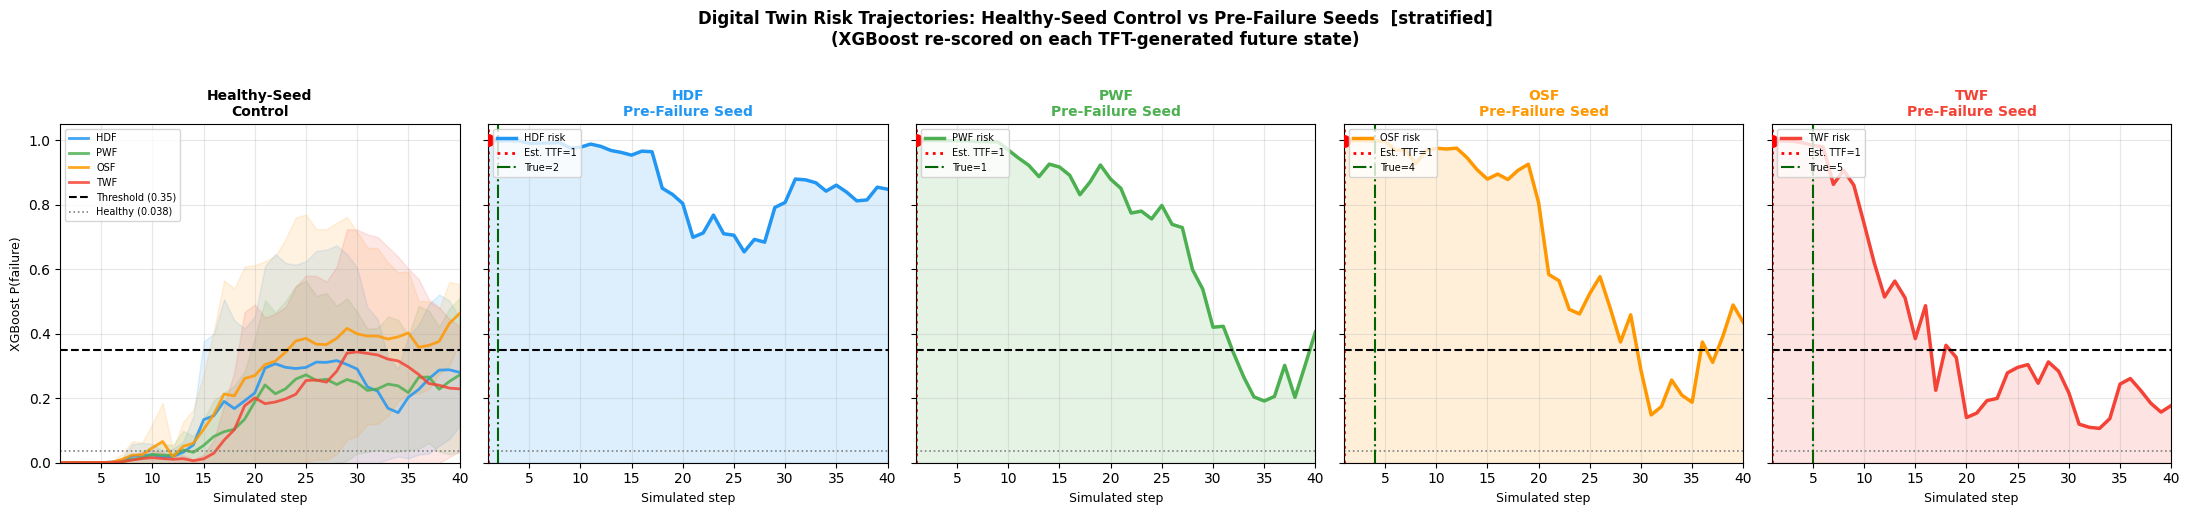

Saved: dt_all_trajectories_hires_stratified.png  (300 dpi)


In [38]:
# ============================================================
# CELL DT-VIZ — 5-Panel High-Res Figure — 300 dpi
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=True)
steps_x   = np.arange(1, N_SIM_STEPS + 1)

# Panel 1: healthy-seed control
ax0 = axes[0]
for ft in GEN_TYPES:
    if ft not in ctrl_results: continue
    all_risks = np.array([r["risk_trajectory"] for r in ctrl_results[ft]])
    mean_r    = all_risks.mean(axis=0)
    std_r     = all_risks.std(axis=0)
    ax0.plot(steps_x, mean_r, color=colors_ft[ft], lw=2.0, label=ft, alpha=0.85)
    ax0.fill_between(steps_x, mean_r - std_r, mean_r + std_r,
                     color=colors_ft[ft], alpha=0.12)

ax0.axhline(BEST_THRESHOLD, color="black", linestyle="--", lw=1.5,
            label=f"Threshold ({BEST_THRESHOLD:.2f})")
ax0.axhline(healthy_baseline, color="gray", linestyle=":", lw=1.2,
            label=f"Healthy ({healthy_baseline:.3f})")
ax0.set_title("Healthy-Seed\nControl", fontsize=10, fontweight="bold")
ax0.set_xlabel("Simulated step", fontsize=9)
ax0.set_ylabel("XGBoost P(failure)", fontsize=9)
ax0.set_xlim(1, N_SIM_STEPS); ax0.set_ylim(0, 1.05)
ax0.legend(fontsize=7, loc="upper left"); ax0.grid(alpha=0.3)

# Panels 2-5: failure-type seeds
for ax, ft in zip(axes[1:], GEN_TYPES):
    if ft not in sim_results: ax.set_visible(False); continue
    col  = colors_ft[ft]
    risk = sim_results[ft]["risk_trajectory"]
    ttf  = sim_results[ft]["time_to_failure_est"]
    ax.plot(steps_x, risk, color=col, lw=2.5, label=f"{ft} risk")
    ax.fill_between(steps_x, risk, alpha=0.15, color=col)
    ax.axhline(BEST_THRESHOLD, color="black", linestyle="--", lw=1.5)
    ax.axhline(healthy_baseline, color="gray", linestyle=":", lw=1.2)
    if ttf is not None:
        ax.axvline(ttf, color="red", linestyle=":", lw=2, label=f"Est. TTF={ttf}")
        ax.scatter([ttf], [risk[ttf-1]], color="red", s=70, zorder=5)
    true_offset = sim_results[ft]["true_fail_offset"]
    if not np.isnan(true_offset):
        ax.axvline(true_offset, color="darkgreen", linestyle="-.", lw=1.5,
                   label=f"True={true_offset:.0f}")
    ax.set_title(f"{ft}\nPre-Failure Seed", fontsize=10, fontweight="bold", color=col)
    ax.set_xlabel("Simulated step", fontsize=9)
    ax.set_xlim(1, N_SIM_STEPS)
    ax.legend(fontsize=7, loc="upper left"); ax.grid(alpha=0.3)

plt.suptitle(
    f"Digital Twin Risk Trajectories: Healthy-Seed Control vs Pre-Failure Seeds  [{SPLIT_MODE}]\n"
    "(XGBoost re-scored on each TFT-generated future state)",
    fontsize=12, y=1.02, fontweight="bold"
)
plt.tight_layout()
plt.savefig(f"dt_all_trajectories_hires{SPLIT_SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: dt_all_trajectories_hires{SPLIT_SUFFIX}.png  (300 dpi)")

In [ ]:
# ============================================================
# RESULTS EXPORT — 
# ============================================================
import json, os

results_s3 = {
    "dataset":          "AI4I",
    "split_mode":       SPLIT_MODE,
    "tft_rmse":         rmse_all,
    "tft_mae":          mae_all,
    "tft_coverage_80":  float(coverage * 100),
    "persist_rmse":     persist_rmse,
    "persist_mae":      persist_mae,
    "ma_rmse":          ma_rmse,
    "ma_mae":           ma_mae,
    "tft_vs_persist_rmse_pct": pct_imp(persist_rmse, rmse_all),
    "tft_vs_ma_rmse_pct":      pct_imp(ma_rmse, rmse_all),
    "xgb_threshold":    BEST_THRESHOLD,
    "xgb_roc_auc":      float(roc_auc_score(y_test, test_proba)),
    "xgb_ap":           float(average_precision_score(y_test, test_proba)),
    "xgb_f1":           float(f1_score(y_test, y_test_pred)),
    "fteph_mean_h":     float(horizon_df["horizon"].mean()),
    "healthy_baseline": healthy_baseline,
}

out_path = f"results_{SPLIT_MODE}.json"
with open(out_path, "w") as f:
    json.dump(results_s3, f, indent=2)
print(f"✓ Saved {out_path}")
print(json.dumps(results_s3, indent=2))

✓ Saved student3_results_stratified.json
{
  "dataset": "AI4I",
  "split_mode": "stratified",
  "tft_rmse": 0.13722196221351624,
  "tft_mae": 0.07856032252311707,
  "tft_coverage_80": 86.51213688818146,
  "persist_rmse": 0.18886440992355347,
  "persist_mae": 0.11350280046463013,
  "ma_rmse": 0.17286235094070435,
  "ma_mae": 0.1084388718008995,
  "tft_vs_persist_rmse_pct": 27.3,
  "tft_vs_ma_rmse_pct": 20.6,
  "xgb_threshold": 0.35,
  "xgb_roc_auc": 0.9918442647499252,
  "xgb_ap": 0.972513222254164,
  "xgb_f1": 0.9244791666666666,
  "fteph_mean_h": 33.2,
  "healthy_baseline": 0.037524428218603134
}
